# Ajustes de gestión y la conciliación del movimiento de la cobertura

- **Nivel:** 2, El método en la práctica
- **Requisitos previos:** los cuadernos 01 a 03 de este tema
- **Tiempo de lectura:** unos 45 minutos

## Objetivos

Al terminar este cuaderno puedes:

- leer la conciliación de IFRS 7 del movimiento de la cobertura y del valor contable bruto por etapa, y decir qué identidades deben cerrar;
- reconstruir con el motor las filas de la conciliación desde un waterfall versionado y juzgarlas con `check_identities`, enunciando con exactitud la base de la tolerancia;
- plantar un defecto en un movimiento y ver qué identidad lo nombra, y ver que un defecto bajo la tolerancia pasa;
- reportar los ajustes de gestión como líneas separadas y atribuidas que nunca entran a la PCE del modelo, y calcular la cobertura total y los diagnósticos de ajustes;
- explicar qué le dice a un validador un ajuste que no se mueve con el escenario.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este cuaderno, con las mismas versiones exactas:

```bash
pip install riskvalidation==0.9.0 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. La celda siguiente importa los paquetes e imprime sus versiones.

In [1]:
# Importar las herramientas e imprimir las versiones con que corren, para compararlas con notebooks/requirements.txt
import dataclasses
import importlib.metadata as md
import json
import math
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))

# Mostrar un valor lógico o una etiqueta del motor en español, también dentro de listas y diccionarios
ETIQUETAS = {
    "green": "verde", "amber": "ámbar", "red": "rojo", "not_evaluated": "no evaluada", "illustrative": "ilustrativa",
    "synthetic-calibrated": "sintética calibrada", "withheld-derived-only": "retenidas, solo derivados", "included": "incluidas",
    "fitted": "ajustado", "challenger-not-run": "retador no ejecutado",
}


def si_no(valor):
    if isinstance(valor, dict):
        return {ETIQUETAS.get(k, k): si_no(v) for k, v in valor.items()}
    if getattr(valor, 'ndim', 0) > 0:
        return si_no(valor.tolist())
    if isinstance(valor, (list, tuple)):
        return [si_no(v) for v in valor]
    if isinstance(valor, str):
        return ETIQUETAS.get(valor, valor)
    return "sí" if valor else "no"

riskvalidation 0.8.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Datos

Se leen dos casos, de tres archivos versionados.

- **C06** al 2008-12-31 (`data/derived/C06/rd-2008-12.json`): préstamos 7(a) de la SBA, Obras del Gobierno de EE. UU., clase de licencia `mirror-allowed`. La conciliación del movimiento de la cobertura y del valor contable bruto por etapa (`outputs.reconciliation`), el waterfall de la cobertura (`outputs.waterfall`), los totales por etapa (`outputs.stage_summary`) y la lista de ajustes (`outputs.overlays`), que está vacía para esta fecha.
- **C07** (`data/derived/C07/base.json` y `data/derived/C07/recession.json`): Banco Andino, un banco **sintético** generado y calibrado a agregados públicos de la CMF, el supervisor de Chile. No es un banco real ni evidencia sobre ningún banco. Su vista IFRS 9 tiene dos ajustes (`outputs.ifrs9_detail.overlays`), cada uno una línea separada, cuyos montos son supuestos del caso (una fracción de la PCE base de un segmento). Los montos están en pesos chilenos (CLP).

La celda siguiente carga los archivos, imprime el waterfall de la cobertura del C06 y las versiones del motor que calcularon los archivos.

In [2]:
# Cargar la fecha de reporte del C06 y los dos escenarios del C07, e imprimir el waterfall de la cobertura del C06
from riskvalidation.provisions import ecl as ecl_engine, overlays as ovl, reconciliation as rec
from riskvalidation.validation import ifrs9

LANG = "es"
ROOT = Path("../../..").resolve()


def read(case, name):
    return json.loads((ROOT / "data" / "derived" / case / name).read_text(encoding="utf-8"))


c06 = read("C06", "rd-2008-12.json")
base, recession = read("C07", "base.json"), read("C07", "recession.json")
out = c06["outputs"]
print("calculados por el motor, C06 y C07:", c06["provenance"]["riskvalidation_version"], base["provenance"]["riskvalidation_version"], "| motor instalado:", md.version("riskvalidation"))
print("el C07 es sintético:", si_no(base["outputs"]["synthetic"]), "|", si_no(base["provenance"]["truth_status"]))
for line in out["waterfall"]["lines"]:
    print(f"{line['id']:15s} {line['amount'] / 1e6:12.3f}  {line['label'][LANG]}")

calculados por el motor, C06 y C07: 0.5.0 0.5.0 | motor instalado: 0.8.1
el C07 es sintético: sí | sintética calibrada
opening              433.600  Cobertura inicial
originations          99.569  Originaciones
transfer-1-2          51.873  Traspaso 1 a 2
transfer-2-3         926.449  Traspaso 2 a 3
transfer-2-1           0.000  Traspaso 2 a 1
remeasurement        391.917  Remedición
macro-update          -9.308  Actualización macro
write-off           -967.317  Castigo
derecognition        -59.777  Baja (pagado o vencido)
closing              867.007  Cobertura final


## Método

IFRS 7 35H pide una conciliación de la cobertura de apertura a la de cierre por etapa, y 35I lo mismo para el valor contable bruto, con los movimientos que explican el cambio: originaciones, traspasos entre etapas, remedición, castigos y bajas. Para cada fila de etapa de cualquiera de las dos tablas, y con $\mathrm{residuo}$ el monto que reporta el motor:

$$\mathrm{residuo} = \mathrm{cierre} - \Bigl(\mathrm{apertura} + \sum_k \mathrm{movimiento}_k\Bigr)$$

El motor de Contraste agrega cuatro identidades entre las tablas y el waterfall: el waterfall cierra (la apertura más sus líneas es su cierre), el cierre del waterfall es la suma de los cierres por etapa, cada línea del waterfall es la suma de los movimientos por etapa con ese identificador de línea, y el cierre de la cobertura de una etapa es su PCE de etapa más el ajuste que se lleva en esa etapa. Los ajustes son líneas separadas (BCBS d350, párrafos 50 y 51; BCE 2024) y entran solo a la cobertura total:

$$\mathrm{CT} = \sum_{E1} \mathrm{PCE}_{12m} + \sum_{E2} \mathrm{PCE}_{\mathrm{vida}} + \sum_{E3} \mathrm{PCE}_{D} + \sum_{\mathrm{POCI}} \Delta\mathrm{PCE} + \sum_k \mathrm{AJ}_k$$

**La base de la tolerancia**, leída en el código del motor en su versión (`provisions/reconciliation.py`): una identidad de dinero cierra cuando su diferencia absoluta es a lo más $\mathrm{tolerancia} \times \max(1, G)$, con $G$ la suma de los montos absolutos de cierre de las filas del valor contable bruto. La tolerancia por defecto es $10^{-6}$, así que la diferencia permitida es una millonésima de la cartera, no una millonésima de unidad de dinero. Es una compuerta interna de Contraste, no un umbral regulatorio.

Los diagnósticos de ajustes (BCE 2024) son la proporción del ajuste en la cobertura total, el desglose por etapa, segmento y destino (nivel de parámetro o nivel total), y si un ajuste positivo está en un escenario que mejora. La regla de etapa para dónde se lleva un ajuste (uno sin etapa va a la Etapa 1) es una convención del contrato del motor, no una regla de IFRS.

### Paso 1: reconstruir con el motor las filas de la conciliación

`allowance_rollforward` y `gca_rollforward` construyen una fila por etapa desde una apertura, un diccionario de movimientos y un cierre, e informan el residuo. Les damos los números versionados del C06 y comparamos el residuo del motor con el versionado. Las filas del valor contable bruto usan los identificadores de línea de IFRS 7 35I, así que un movimiento fuera de la lista se rechaza.

In [3]:
# Reconstruir las filas por etapa de ambas conciliaciones desde los números versionados y comparar los residuos
recon = out["reconciliation"]


def moves(row):
    return {m["line_id"]: m["amount"] for m in row["movements"]}


allowance = [rec.allowance_rollforward(r["stage"], r["opening"], moves(r), r["closing"]) for r in recon["allowance"]]
gca = [rec.gca_rollforward(r["stage"], r["opening"], moves(r), r["closing"]) for r in recon["gross_carrying_amount"]]
for table, rows, committed in (("35H", allowance, recon["allowance"]), ("35I", gca, recon["gross_carrying_amount"])):
    for row, source in zip(rows, committed):
        print(table, row.stage, "| apertura, millones:", round(row.opening / 1e6, 3), "| cierre, millones:", round(row.closing / 1e6, 3), "| residuo, motor:", f"{row.residual:.0e}", "| versionado:", f"{source['residual']:.0e}")
try:
    rec.gca_rollforward("stage1", 1.0, {"coupon": 1.0}, 2.0)
except ValueError as error:
    print("rechazado:", type(error).__name__, "| identificadores válidos:", rec.GCA_LINE_IDS)

35H stage1 | apertura, millones: 433.354 | cierre, millones: 798.078 | residuo, motor: -1e-07 | versionado: -1e-07
35H stage2 | apertura, millones: 0.246 | cierre, millones: 68.929 | residuo, motor: 0e+00 | versionado: 0e+00
35H stage3 | apertura, millones: 0.0 | cierre, millones: 0.0 | residuo, motor: 0e+00 | versionado: 0e+00
35I stage1 | apertura, millones: 47338.013 | cierre, millones: 46716.271 | residuo, motor: 0e+00 | versionado: 0e+00
35I stage2 | apertura, millones: 7.734 | cierre, millones: 531.345 | residuo, motor: -1e-07 | versionado: -1e-07
35I stage3 | apertura, millones: 0.0 | cierre, millones: 0.0 | residuo, motor: 0e+00 | versionado: 0e+00
rechazado: ValueError | identificadores válidos: ('originations', 'transfer-1-2', 'transfer-2-3', 'transfer-2-1', 'transfer-3-2', 'repayments', 'write-off', 'derecognition', 'other')


### Paso 2: las identidades y su tolerancia

`identity_residuals` devuelve el residuo absoluto de cada identidad por nombre y `check_identities` los nombres de las que fallan. Necesitan las filas, las líneas del waterfall y la PCE por etapa, que es el `stage_summary` versionado. La celda imprime las identidades con sus residuos, el valor contable bruto total $G$ y el límite absoluto $10^{-6} \times G$, y corre la prueba propia del motor `reconciliation_identities`, que devuelve un `TestResult`.

In [4]:
# Juzgar las identidades, imprimir la base de la tolerancia y correr la prueba propia del motor
lines = out["waterfall"]["lines"]
stage_ecl = {r["stage"]: r["ecl"] for r in out["stage_summary"]["rows"]}
residuals = rec.identity_residuals(allowance, gca, lines, stage_ecl)
for name, value in residuals.items():
    print(f"{name:40s} {value:10.3e}")
G = rec.gross_total(gca)
print("G, millones:", round(G / 1e6, 1), "| límite absoluto 1e-6 x G, USD:", round(1e-6 * max(1.0, G), 1))
print("identidades que fallan:", rec.check_identities(allowance, gca, lines, stage_ecl))

test = ifrs9.reconciliation_identities(allowance, gca, lines, stage_ecl, model_id="c06")
print("prueba del motor:", si_no(test.light.value), "| mayor residuo:", f"{test.metric:.0e}", "| tolerancia, USD:", round(test.extras["tolerance"], 1))
committed = [t for t in c06["tests"] if t["test_id"] == "ifrs9.reconciliation_identities"][0]
print("fila versionada:", si_no(committed["light"]), "| misma luz:", si_no(committed["light"] == test.light.value))

allowance-rollforward:stage1              1.192e-07
allowance-rollforward:stage2              0.000e+00
allowance-rollforward:stage3              0.000e+00
gca-rollforward:stage1                    0.000e+00
gca-rollforward:stage2                    1.192e-07
gca-rollforward:stage3                    0.000e+00
waterfall-closes                          0.000e+00
waterfall-equals-stage-closings           0.000e+00
waterfall-lines-equal-movements           0.000e+00
stage-closing-equals-ecl:stage1           0.000e+00
stage-closing-equals-ecl:stage2           0.000e+00
stage-closing-equals-ecl:stage3           0.000e+00
G, millones: 47247.6 | límite absoluto 1e-6 x G, USD: 47247.6
identidades que fallan: []
prueba del motor: verde | mayor residuo: 1e-07 | tolerancia, USD: 47247.6
fila versionada: verde | misma luz: sí


### Paso 3: plantar un defecto y ver quién lo nombra

Una compuerta vale lo que detecta. La celda copia la fila de la Etapa 1, le agrega un movimiento que el cierre no lleva y pregunta a `check_identities` qué identidades fallan: primero con un defecto de 1.000.000 USD, luego con uno de 10.000 USD, luego con la tolerancia ajustada a $10^{-9}$ para los mismos 10.000 USD. El límite es una millonésima de $G$, cerca de 47.000 USD, así que el segundo defecto pasa con la tolerancia por defecto. Ese es el precio de una base relativa, y la razón por la que un validador enuncia la base junto al resultado.

In [5]:
# Agregar un movimiento que el cierre no lleva y preguntar qué identidades fallan, con dos tolerancias
def with_defect(amount):
    first = recon["allowance"][0]
    broken = rec.allowance_rollforward(first["stage"], first["opening"], {**moves(first), "remeasurement": moves(first)["remeasurement"] + amount}, first["closing"])
    return [broken] + allowance[1:]


for amount, tolerance in ((1_000_000.0, 1e-6), (10_000.0, 1e-6), (10_000.0, 1e-9)):
    failing = rec.check_identities(with_defect(amount), gca, lines, stage_ecl, tolerance=tolerance)
    print("defecto, USD", int(amount), "| tolerancia", tolerance, "| límite, USD:", round(tolerance * G, 1), "| fallan:", failing)

defecto, USD 1000000 | tolerancia 1e-06 | límite, USD: 47247.6 | fallan: ['allowance-rollforward:stage1', 'waterfall-lines-equal-movements']
defecto, USD 10000 | tolerancia 1e-06 | límite, USD: 47247.6 | fallan: []
defecto, USD 10000 | tolerancia 1e-09 | límite, USD: 47.2 | fallan: ['allowance-rollforward:stage1', 'waterfall-lines-equal-movements']


### Paso 4: el waterfall y las tablas por etapa, dibujados

El waterfall es la cuenta de toda la cobertura. Cada barra es una línea: la apertura, los movimientos y el cierre. La celda lo dibuja con las líneas leídas en el paso 1. Nota el traspaso de la Etapa 2 a la Etapa 3 y el castigo de casi el mismo monto: el archivo no tiene saldo en la Etapa 3 a una fecha (hallazgo `F-NO-DELINQUENCY`), así que los préstamos llegan al incumplimiento, se castigan en el año y no dejan cobertura en la Etapa 3 al cierre.

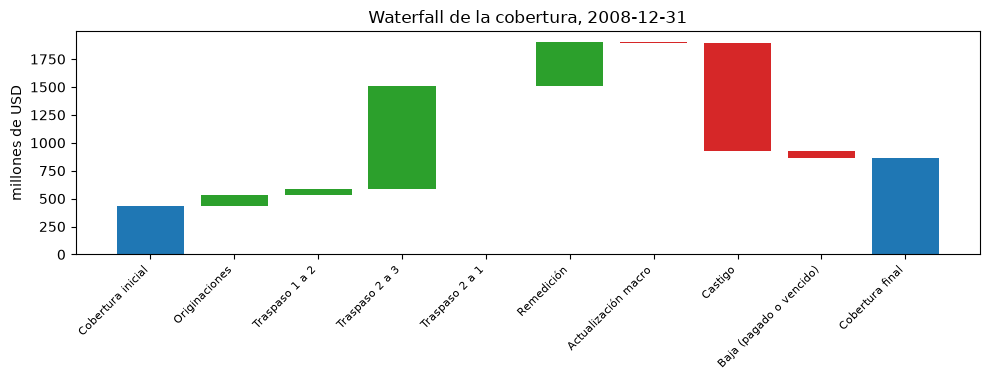

In [6]:
# Dibujar el waterfall de la cobertura: la apertura, cada movimiento y el cierre
fig, ax = plt.subplots(figsize=(10, 3.9))
running = 0.0
labels, positions = [], []
for i, line in enumerate(lines):
    amount = line["amount"] / 1e6
    if line["kind"] in ("opening", "closing"):
        ax.bar(i, amount, color="tab:blue")
        running = amount
    else:
        ax.bar(i, abs(amount), bottom=running if amount >= 0 else running + amount, color="tab:green" if amount >= 0 else "tab:red")
        running += amount
    labels.append(line["label"][LANG])
ax.set_xticks(range(len(lines)))
ax.set_xticklabels(labels, rotation=45, ha="right", fontsize=8)
ax.set_ylabel("millones de USD")
ax.set_title("Waterfall de la cobertura, 2008-12-31")
fig.tight_layout()
plt.show()

### Paso 5: ajustes como líneas separadas

El C06 no tiene ajustes a esta fecha. La vista IFRS 9 del C07 tiene dos, versionados como líneas con un identificador, un segmento, una etapa y un monto. El `Overlay` del motor pide más: un método, un destino, un efecto en las etapas y una fecha de revisión. El artefacto guarda el destino solo en agregado (`by_target` de `ifrs9.overlay_diagnostics` versionado) y no la fecha de revisión, así que la celda toma el destino de esa apertura versionada (el ajuste de 97,2 millones es igual al monto `lgd` versionado y el de 226,9 millones al monto `ead`) y fija la fecha de revisión como un **insumo de la lección**. El método se lee de las etiquetas («experto»). La celda construye luego las líneas de ajuste, la cobertura total y los diagnósticos, y los compara con los números versionados.

In [7]:
# Construir los ajustes del motor desde las líneas versionadas y calcular las líneas, la cobertura total y los diagnósticos
detail = base["outputs"]["ifrs9_detail"]
row = [t for t in base["tests"] if t["test_id"] == "ifrs9.overlay_diagnostics"][0]
by_target = {amount: target for target, amount in row["extras"]["by_target"].items() if amount}
REVIEW_DATE = "2026-08-31"  # insumo de la lección: el artefacto no guarda la fecha de revisión
overlays = [
    ovl.Overlay(id=o["id"], rationale_en=o["label"]["en"], rationale_es=o["label"]["es"], method="expert", target=by_target[o["amount"]],
                segment_id=o["segment_id"], stage=o["stage"], amount=o["amount"], staging_effect="none", review_date=REVIEW_DATE, currency="CLP")
    for o in detail["overlays"]
]
for line in ovl.overlay_lines(overlays):
    print(line["id"], "|", line["stage"], "| monto, millones de CLP:", round(line["amount"] / 1e6, 3))

stage_model = {r["stage"]: r["ecl"] for r in detail["stage_summary"] if r["stage"] != "poci"}
model_total = sum(stage_model.values())
total = ovl.total_allowance(model_total, overlays)
print("PCE del modelo, millones de CLP:", round(model_total / 1e6, 1), "| cobertura total:", round(total / 1e6, 1), "| provisión IFRS 9 versionada:", round(base["impact"]["provision_ifrs9"]["value"] / 1e6, 1))
print("llevado por etapa, millones:", {k: round(v / 1e6, 1) for k, v in rec.carried_by_stage(overlays).items()})

diag = ifrs9.overlay_diagnostics(overlays, stage_model, 0, model_id="c07")
print("proporción del ajuste en la cobertura:", round(diag.metric, 6), "| versionada:", round(row["metric"], 6), "|", si_no(diag.light.value), "| por destino, millones:", {k: round(v / 1e6, 1) for k, v in diag.extras["by_target"].items()})
print("versiones del motor, calculado e instalado:", base["provenance"]["riskvalidation_version"], md.version("riskvalidation"))

overlay-OVL-CARDS | stage1 | monto, millones de CLP: 226.934
overlay-OVL-HOUSING | stage2 | monto, millones de CLP: 97.196
PCE del modelo, millones de CLP: 97267.9 | cobertura total: 97592.0 | provisión IFRS 9 versionada: 97592.0
llevado por etapa, millones: {'stage1': 226.9, 'stage2': 97.2, 'stage3': 0.0, 'poci': 0.0}
proporción del ajuste en la cobertura: 0.003321 | versionada: 0.003321 | verde | por destino, millones: {'pd': 0.0, 'lgd': 97.2, 'ead': 226.9, 'staging-share': 0.0}
versiones del motor, calculado e instalado: 0.5.0 0.8.1


### Paso 6: qué hace cambiar de color a los diagnósticos

La luz de `overlay_diagnostics` lee la proporción del ajuste en la cobertura (ámbar sobre 10 %, rojo sobre 25 %) y la dirección: un ajuste positivo en un escenario que mejoró es inconsistente. La celda reconstruye los mismos ajustes escalados por 100, 200 y 300 para ver la proporción cruzar los límites, y pasa una dirección de escenario de $-1$ (mejora) para ver la verificación de dirección. Son **corridas hipotéticas sobre los ajustes versionados**, no datos.

In [8]:
# Escalar los ajustes e invertir la dirección del escenario para ver actuar la proporción y la verificación de dirección
for factor in (1, 100, 200, 300):
    scaled = [dataclasses.replace(o, amount=o.amount * factor) for o in overlays]
    d = ifrs9.overlay_diagnostics(scaled, stage_model, 0)
    print("ajustes multiplicados por", factor, "| proporción:", round(d.metric, 4), "|", si_no(d.light.value))
improving = ifrs9.overlay_diagnostics(overlays, stage_model, -1)
print("escenario que mejora, ajustes positivos:", si_no(improving.light.value), "| dirección consistente:", si_no(improving.extras["direction_consistent"]))

ajustes multiplicados por 1 | proporción: 0.0033 | verde
ajustes multiplicados por 100 | proporción: 0.2499 | ámbar
ajustes multiplicados por 200 | proporción: 0.3999 | rojo
ajustes multiplicados por 300 | proporción: 0.4999 | rojo
escenario que mejora, ajustes positivos: ámbar | dirección consistente: no


### Paso 7: un ajuste que no sigue al escenario

Los ajustes del C07 están fijados en el caso en 10 % y 8 % de la PCE **base** de su segmento. La variante de recesión provisiona el mismo banco bajo un escenario más duro. La celda compara la PCE del modelo, el ajuste y la proporción del ajuste en la cobertura en las dos variantes. Un validador lee de aquí que el ajuste no responde al escenario que cambió el modelo: se dimensionó una vez, y su proporción se achica a medida que crece la PCE del modelo.

In [9]:
# Comparar la PCE del modelo y el ajuste de las variantes base y recesión de Banco Andino
for name, art in (("base", base), ("recession", recession)):
    d = art["outputs"]["ifrs9_detail"]
    model = sum(r["ecl"] for r in d["stage_summary"])
    print(f"{name:10s} PCE del modelo, millones de CLP: {model / 1e6:10.1f} | ajustes: {d['overlays_total'] / 1e6:8.1f} | proporción: {d['overlays_total'] / (model + d['overlays_total']):.5f} | escenario:", art["outputs"]["scenario_id"])
print("los montos de los ajustes son idénticos en ambas variantes:", si_no([o["amount"] for o in base["outputs"]["ifrs9_detail"]["overlays"]] == [o["amount"] for o in recession["outputs"]["ifrs9_detail"]["overlays"]]))

base       PCE del modelo, millones de CLP:    97267.9 | ajustes:    324.1 | proporción: 0.00332 | escenario: base
recession  PCE del modelo, millones de CLP:   169463.6 | ajustes:    324.1 | proporción: 0.00191 | escenario: recession
los montos de los ajustes son idénticos en ambas variantes: sí


## Resultados

- **La conciliación cierra.** Las seis filas por etapa (tres de la cobertura, tres del valor contable bruto) se reconstruyen con el motor y tienen residuos no mayores que 1,2e-07 USD, iguales a los versionados. En la Etapa 1 la cobertura pasa de 433,354 a 798,078 millones de USD y en la Etapa 2 de 0,246 a 68,929; el valor contable bruto de la Etapa 1 pasa de 47.338,013 a 46.716,271 millones. Un movimiento fuera de la lista de IFRS 7 35I (`coupon`) se rechaza y se listan los identificadores válidos.
- **Doce identidades se cumplen.** Los residuos de las doce identidades son a lo más 1,2e-07 USD, `check_identities` devuelve una lista vacía y la prueba propia del motor está verde con la misma luz que la fila versionada. El waterfall abre en 433,600 millones, que es la suma de las tres aperturas por etapa, y cierra en 867,007, la cobertura del cuaderno 03.
- **La tolerancia es relativa, y eso es una propiedad que hay que enunciar.** $G$ es 47.247,6 millones de USD, así que el límite por defecto es 47.247,6 USD. Un defecto de 1.000.000 USD se detecta y se nombra dos veces (`allowance-rollforward:stage1` y `waterfall-lines-equal-movements`); un defecto de 10.000 USD pasa con la tolerancia por defecto y se detecta cuando la tolerancia se ajusta a 1e-9 (un límite de 47,2 USD). La compuerta protege a la cartera de un error del tamaño de un movimiento, no de un redondeo de unos pocos miles de USD.
- **La Etapa 3 cierra en cero por la construcción de los datos.** El traspaso de la Etapa 2 a la Etapa 3 es 926,449 millones y el castigo es $-967{,}317$ millones: los préstamos incumplen y se castigan dentro del año, y no queda cobertura de Etapa 3 a la fecha (hallazgo `F-NO-DELINQUENCY`).
- **Los ajustes son líneas, y el total concilia.** Los dos ajustes de Banco Andino son 226,934 millones de CLP (tarjetas, Etapa 1, destino `ead`) y 97,196 (hipotecarios de PVG alto, Etapa 2, `lgd`). La PCE del modelo es 97.267,9 millones, la cobertura total 97.592,0, igual a la provisión IFRS 9 versionada, y la proporción de los ajustes es 0,003321 (0,33 %), igual a la fila versionada y verde. Llevado por etapa: 226,9 en la Etapa 1 y 97,2 en la Etapa 2.
- **Los diagnósticos se mueven como dicen las reglas.** Los mismos ajustes multiplicados por 100 son 24,99 % de la cobertura (ámbar, justo bajo el límite rojo de 25 %), multiplicados por 200 o 300 son rojos. En un escenario que mejora, un ajuste positivo hace fallar la verificación de dirección y deja la luz en ámbar, aunque la proporción sea pequeña. Son corridas hipotéticas.
- **Un ajuste que no sigue al escenario.** En la variante de recesión la PCE del modelo crece de 97.267,9 a 169.463,6 millones de CLP y los ajustes se quedan en 324,1, así que su proporción baja de 0,33 % a 0,19 %. Un validador lo lee como un ajuste dimensionado una vez sobre el caso base; el BCE (2024) pide que los ajustes se apoyen en un método, como una simulación o un análisis de escenarios, lo que les permitiría moverse con el escenario.

Lo que este cuaderno no muestra: el cierre de las identidades es una afirmación sobre la consistencia aritmética de las tablas, no sobre si la cobertura es correcta, y el motor no declara cumplimiento. La fecha de revisión de los ajustes es un insumo de la lección, y el C07 es un banco sintético.

## Resumen

- La conciliación de IFRS 7 del movimiento de la cobertura y del valor contable bruto se reconstruye fila por fila con el motor, y doce identidades atan las tablas por etapa al waterfall.
- La compuerta cierra con una tolerancia de una millonésima del valor contable bruto de la cartera, así que detecta un error del tamaño de un movimiento y deja pasar unos pocos miles de USD; un validador enuncia la base junto al resultado.
- Los ajustes son líneas separadas y atribuidas que entran solo a la cobertura total, nunca a la PCE del modelo ni a la de etapa; el motor lleva un ajuste sin etapa en la Etapa 1 por convención.
- Los diagnósticos de ajustes leen la proporción de la cobertura, su desglose y la dirección frente al escenario; un ajuste fijado en el caso no sigue a un escenario más duro.
- Una identidad que cierra dice que las tablas concuerdan entre sí, no que la cobertura sea adecuada.

**Qué probar a continuación.** Planta un defecto en otro movimiento, o en la tabla del valor contable bruto, y lee qué identidades lo nombran; cambia `REVIEW_DATE` y ve que los totales no se mueven. Después sigue con el cuaderno 05, que valida toda la batería en seis fechas de reporte.

## Referencias

- IASB, IFRS 9 Instrumentos financieros (julio de 2014), tal como lo adopta el Reglamento (UE) 2016/2067 de la Comisión, párrafos 5.5 y B5.5, y las enmiendas a la IFRS 7, 35A a 35N. https://eur-lex.europa.eu/legal-content/EN/TXT/HTML/?uri=CELEX:32016R2067
- ECB Banking Supervision (2024), IFRS 9 overlays and model improvements for novel risks, julio de 2024. https://www.bankingsupervision.europa.eu/ecb/pub/pdf/ssm.IFRS9novelrisks_202407~5e0eb30b5c.en.pdf
- BCBS (2015), Guidance on credit risk and accounting for expected credit losses (d350), párrafos 36, 50 y 51 y párrafo A26 del anexo. https://www.bis.org/bcbs/publ/d350.htm
- EBA (2023), IFRS 9 implementation by EU institutions, informe de seguimiento 2023, EBA/Rep/2023/36, párrafos 29 a 33 y 94 a 118. https://www.eba.europa.eu/sites/default/files/2023-11/25b12d35-9c28-4335-a589-166c77198920/Final%20Report%20on%20IFRS9%20implementation%20by%20EU%20institutions.pdf